# Description

This notebook examines ...

The name of this notebook should follow the format: `<tool>.API.ipynb` (e.g., `pycaret.API.ipynb` for exploring the pycaret API).

References:
- Add description of what the notebook does.
- Point to references, e.g. (tool.API.md)
- Add citations.
- Keep the notebook flow clear.
- Comments should be imperative and have a period at the end.
- Your code should be well commented.

Guide: https://github.com/causify-ai/helpers/blob/master/docs/coding/all.jupyter_notebook.how_to_guide.md

New link: https://github.com/causify-ai/helpers/blob/master/docs/tools/notebooks/all.jupyter_notebook.how_to_guide.md

# 1. Import Packages and Load Financial Data

## 1.1. Import Packages

In [81]:
%load_ext autoreload
%autoreload 2

# System libraries.
import os
import logging
import shutil

# Third-party libraries.
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib
import matplotlib.pyplot as plt

# Following lines ensure inline plots render properly with installed version of matplotlib
if not hasattr(matplotlib.rcParams, "_get"):
    matplotlib.rcParams._get = matplotlib.rcParams.get

# Core packages installed for project.

import yfinance as yf
import tensorflow as tf
import autokeras as ak

# Import local functions:
import autokeras_utils as utils

# Use this for most notebooks.
import helpers.hdbg as hdbg
import helpers.hnotebook as hnotebook

_LOG = logging.getLogger(__name__)

# Initialize notebook configuration and logging.
hdbg.init_logger(verbosity=logging.INFO)
hnotebook.config_notebook()

# Set plots to default style:
plt.style.use("default")

# Convert `display` into `print()`.
try:
    from IPython.display import display
except ImportError:
    display = print  # type: ignore

print("TF: ", tf.__version__, "AK: ", ak.__version__, "YF: ", yf.__version__)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
TF:  2.10.1 AK:  1.1.0 YF:  1.8.0


In [10]:
# # To install additional packages, use:
# import helpers.hmodule as hmodule
# hmodule.install_module_if_not_present(
#     ["pycaret"],
#     use_activate=True,
#     use_sudo=False,
#     venv_path="/opt/venv",
# )

## 1.2. Load Financial Data

In [14]:
# Load SPY dataframe from CSV file using function:

spy_df = utils.load_volatility_timeseries()
spy_df

Loaded 5283 rows and 6 columns from: data/spy_volatility_timeseries_2005_2025.csv.

Summary Statistics:
              Open         High          Low        Close   Log_return   GK_variance
count  5283.000000  5283.000000  5283.000000  5283.000000  5283.000000  5.283000e+03
mean    223.784215   225.018927   222.432924   223.815212     0.000401  9.594277e-05
std     155.475934   156.239608   154.621329   155.504401     0.012011  2.877906e-04
min      49.441075    50.932677    48.822624    49.557495    -0.115886  7.464611e-07
25%      97.754010    98.295882    97.089242    97.728291    -0.003955  1.581894e-05
50%     170.239816   171.102968   169.551185   170.296417     0.000716  3.399318e-05
75%     313.433346   314.924630   309.995047   312.316879     0.005786  7.869873e-05
max     685.287481   686.299535   683.928104   685.029480     0.135577  6.674885e-03


,Open,High,Low,Close,Log_return,GK_variance
Date,,,,,,
2005-01-03,81.821624,81.956246,80.704286,80.973526,-0.004727,0.000077
2005-01-04,81.081254,81.135103,79.721601,79.984108,-0.012294,0.000083
2005-01-05,79.923517,80.266798,79.425427,79.432159,-0.006925,0.000041
2005-01-06,79.721573,80.199471,79.600416,79.835999,0.005071,0.000027
2005-01-07,80.078306,80.253312,79.512902,79.721565,-0.001434,0.000035
...,...,...,...,...,...,...
2025-12-24,682.618320,685.476005,682.469458,685.029480,0.003511,0.000005
2025-12-26,685.287481,686.299535,683.928104,684.960022,-0.000101,0.000006
2025-12-29,682.211448,683.858617,680.752870,682.519043,-0.003570,0.000010


In [ ]:
# Remove directory from previous run of "time_series_forecaster", including the stale failed oracle folder
shutil.rmtree("./time_series_forecaster", ignore_errors=True)

# 2. Prepare Data for `TimeSeriesForecaster`

In [31]:
# Create log_GK_variance column to scale GK_variance on tighter range; clip small values of GK_variance to prevent NaN/infinity values in log 
spy_df["log_GK_variance"] = np.log(spy_df["GK_variance"].clip(lower=1e-12))

# Define features X and target variable y:
feature_cols = ["Log_return", "log_GK_variance"]
target_col = "log_GK_variance"

# Split out X and y:
X = spy_df[feature_cols].astype("float64")
y = spy_df[target_col].astype("float64")

# Define chronological train/validation/test split to be 70% / 15% / 15%:
n = spy_df.shape[0]
train_end = int(n * 0.7)
val_end = int(n * 0.85)

# Define train, validation, test datasets:
x_train, y_train = X[:train_end], y[:train_end]
x_val, y_val = X[train_end:val_end], y[train_end:val_end]
x_test, y_test = X[val_end:], y[val_end:]


print(x_train.shape)  # (3698, 2)
print(y_train.shape)  # (3698,)
print(x_val.shape)  # (792, 2)
print(y_val.shape)  # (792,)
print(x_test.shape)  # (793, 2)
print(y_test.shape)  # (793,)


(3698, 2)
(3698,)
(792, 2)
(792,)
(793, 2)
(793,)


# 3. Run AutoKeras `TimeSeriesForecaster`

Search the Forecaster: Fit `TimeseriesForecaster` with a lookback of 22 days, a fixed max_trials, a cap on the epochs, and five random seeds, then export the best model.

In [57]:
# Search through 5 random seeds in a loop; save best model for each seed.

lookback = 22
batch_size = 11 # Divides lookback=22 evenly, matching Issue #1554 workaround
trial_max = 2
epoch_cap = 5
seeds = [1,6,7,9,42]
best_val_mse = float("inf")
best_forecaster = None
best_seed = None
results = []
project_dir = "time_series_forecaster_api"
os.makedirs(project_dir, exist_ok=True)

for seed in seeds:
    tf.keras.backend.clear_session() 
    with utils.TeeOutput(f"{project_dir}/seed_{seed}_output.txt"): 
        csv_path = f"{project_dir}/seed_{seed}_history.csv"
        csv_logger = tf.keras.callbacks.CSVLogger(csv_path, append=False)
        
        forecaster = ak.TimeseriesForecaster(
            lookback=lookback,
            predict_from=1,
            predict_until=1,
            max_trials=trial_max,
            directory=project_dir,
            project_name=f"seed_{seed}",
            overwrite=True,
            seed=seed,
        )
    
        # Search and train using Epoch cap and explicitly defined validation data:
        forecaster.fit(
            x=x_train,
            y=y_train,
            validation_data=(x_val,y_val),
            epochs=epoch_cap,
            batch_size=batch_size,
            callbacks=[csv_logger],
        )
    
        # Evaluate on validation data; returns [loss, mean_squared_error]:
        val_loss, val_mse = forecaster.evaluate(x_val, y_val, batch_size=batch_size, verbose=0)
    
        # Evaluate on test data; returns [loss, mean_squared_error]:
        test_loss, test_mse = forecaster.evaluate(x_test, y_test, batch_size=batch_size, verbose=0)
        
        # Output validation and test results:
        results.append({"seed": seed, "val_mse": val_mse, "test_mse": test_mse})
        print(f"Seed {seed} | Val MSE: {val_mse:.6f} | Test MSE: {test_mse:.6f}")
    
        # Check to see if this is best overall model; if so, save
        if val_mse < best_val_mse:
            best_val_mse = val_mse
            best_forecaster = forecaster
            best_seed = seed
            best_test_mse = test_mse
            best_csv_path = csv_path
    
        # Export best keras model for this seed:
        best_model = forecaster.export_model()
        best_model.summary()

# Export best overall model:
print(f"\nBest seed: {best_seed} (Val MSE: {best_val_mse:.6f}) ")
best_overall_model = best_forecaster.export_model()
best_overall_model.summary()


Trial 2 Complete [00h 00m 17s]
val_loss: 2.42683482170105

Best val_loss So Far: 2.1323702335357666
Total elapsed time: 00h 00m 35s
INFO:tensorflow:Oracle triggered exit
INFO  Oracle triggered exit
Epoch 1/5
334/334 [==============================] - 6s 10ms/step - loss: 86.4116 - mean_squared_error: 86.4116 - val_loss: 60.0402 - val_mean_squared_error: 60.0402
Epoch 2/5
334/334 [==============================] - 3s 8ms/step - loss: 50.3405 - mean_squared_error: 50.3405 - val_loss: 35.0169 - val_mean_squared_error: 35.0169
Epoch 3/5
334/334 [==============================] - 3s 8ms/step - loss: 30.3317 - mean_squared_error: 30.3317 - val_loss: 20.5599 - val_mean_squared_error: 20.5599
Epoch 4/5
334/334 [==============================] - 3s 8ms/step - loss: 17.9907 - mean_squared_error: 17.9907 - val_loss: 11.6515 - val_mean_squared_error: 11.6515
Epoch 5/5
334/334 [==============================] - 3s 8ms/step - loss: 10.3234 - mean_squared_error: 10.3234 - val_loss: 6.4190 - val_mean_

# 4. Examine Results of AutoKeras TimeSeriesForecaster Search

## 4.1. Validation and Test Mean-Squared Error (MSE) across seeds

The MSE is computed using the natural logarithm of the the Garman-Klass variance as the target variable. We compute loss using MSE.


In [73]:
# Output Validation and Test Mean-Squared Error (MSE) for each seed:

pd.DataFrame(results)

,seed,val_mse,test_mse
0,1,2.773240,3.102344
1,6,97.303711,105.966202
2,7,19.223972,22.533106
3,9,1.844407,1.076959
4,42,6.419011,7.820064


## 4.2 Training and Validation Loss across Epochs 

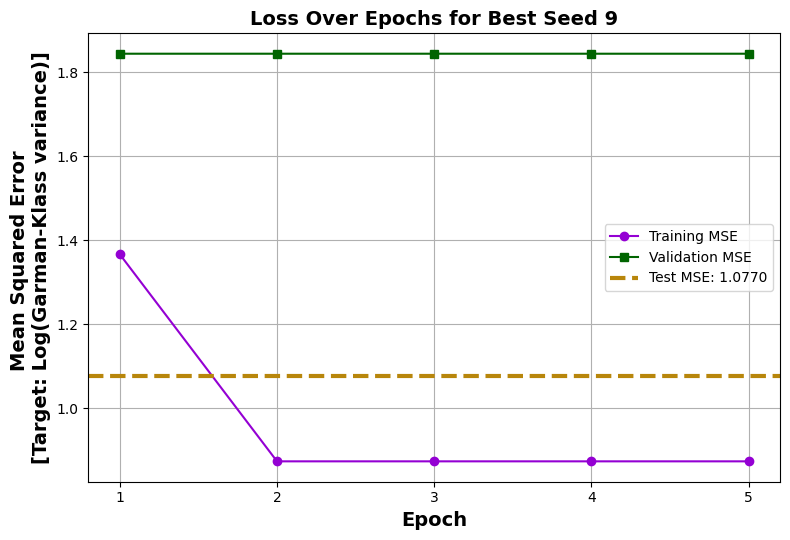

In [109]:
# Plot comparison of training and validation loss across epochs for best seed:

utils.plot_train_val_loss(best_csv_path,epoch_cap,best_test_mse,title=f"Loss Over Epochs for Best Seed {best_seed}",
                    save_plot=True,save_filename=f"plots/api_TrainVal_LossOverEpochs_BestSeed_{best_seed}.png")

In [147]:
# Build 22-day sliding window across x_test for best_overall_model:

X_test_windows = np.array([
    x_test.values[i - lookback + 1:i + 1]
    for i in range(lookback - 1, len(x_test))
])

# Generate next-day predictions and align y test dates:
# Add .ravel() to change shape from (771,1) to (771,); values remain same.
y_pred_test = best_overall_model.predict(X_test_windows[:-1], verbose=0).ravel()
# y_test is Pandas series; use iloc to get rows aligned by date with y_pred_test
y_test_aligned = y_test.iloc[lookback:]

print("Aligned shapes: ",y_test_aligned.shape,y_pred_test.shape)

y_test_aligned

Aligned shapes:  (771,) (771,)


Date
2022-12-05    -9.248903
2022-12-06    -8.833319
2022-12-07   -10.047245
2022-12-08    -9.892798
2022-12-09    -9.771504
                ...    
2025-12-24   -12.234781
2025-12-26   -12.040168
2025-12-29   -11.485197
2025-12-30   -12.432239
2025-12-31   -11.364632
Name: log_GK_variance, Length: 771, dtype: float64

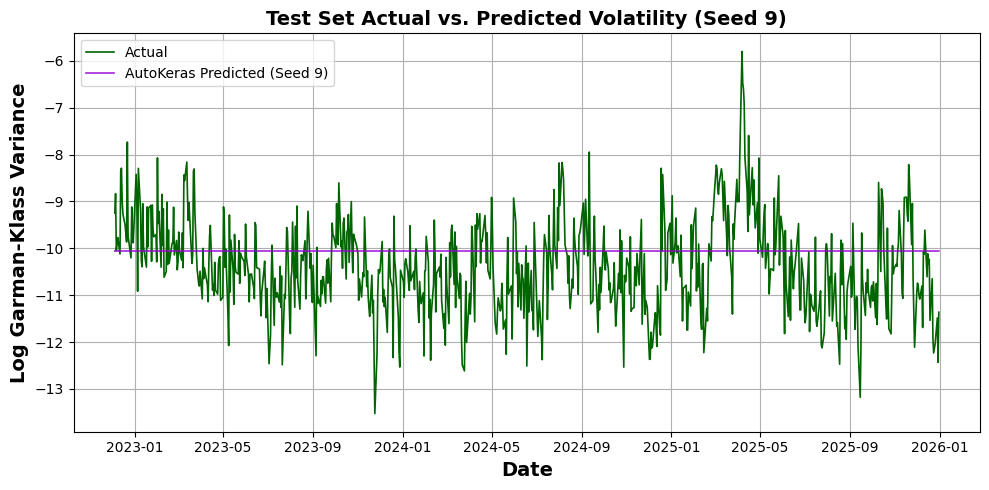

In [134]:
# Plot actual versus predicted Log(Garman-Klass variance)
# Will create function for this later
save_plot = True
save_filename = f"plots/api_TestActualVPredVolatility_BestSeed_{best_seed}.png"

plt.figure(figsize=(10,5))
plt.plot(y_test_aligned.index,y_test_aligned.values,label="Actual",
         color="darkgreen",linewidth=1.2)
plt.plot(y_test_aligned.index,y_pred_test,label=f"AutoKeras Predicted (Seed {best_seed})",
         color="darkviolet",alpha=0.85,linewidth=1.2)
plt.xlabel("Date",fontweight="bold",fontsize=14)
plt.ylabel("Log Garman-Klass Variance",fontweight="bold",fontsize=14)
plt.title(f"Test Set Actual vs. Predicted Volatility (Seed {best_seed})",
          fontweight="bold",fontsize=14)
plt.legend()
plt.grid(True)
plt.tight_layout()
if save_plot and save_filename:
    parent_dir = os.path.dirname(save_filename)
    if parent_dir:
        os.makedirs(parent_dir, exist_ok=True)
    plt.savefig(save_filename,dpi=300)
plt.show()


In [152]:
check_df = pd.DataFrame({
    "X_log_GK_var_today": X["log_GK_variance"],
    "y_target": y,
})
display(check_df.head(5))

test_check_df = pd.DataFrame({
    "x_test_log_GK_var": x_test["log_GK_variance"].iloc[lookback:].values,
    "y_test_aligned": y_test_aligned.values,
    "y_pred_test": y_pred_test,
}, index=y_test_aligned.index)
display(test_check_df.head(5))


,X_log_GK_var_today,y_target
Date,,
2005-01-03,-9.477589,-9.477589
2005-01-04,-9.399770,-9.399770
2005-01-05,-10.106122,-10.106122
2005-01-06,-10.508170,-10.508170
2005-01-07,-10.252930,-10.252930


,x_test_log_GK_var,y_test_aligned,y_pred_test
Date,,,
2022-12-05,-9.248903,-9.248903,-10.058161
2022-12-06,-8.833319,-8.833319,-10.058155
2022-12-07,-10.047245,-10.047245,-10.058148
2022-12-08,-9.892798,-9.892798,-10.058159
2022-12-09,-9.771504,-9.771504,-10.058161


## Make the notebook flow clear
Each notebook needs to follow a clear and logical flow, e.g:
- Load data
- Compute stats
- Clean data
- Compute stats
- Do analysis
- Show results

In [ ]:
class Template:
    """
    Brief imperative description of what the class does in one line, if needed.
    """

    def __init__(self) -> None:
        """
        Initialize the Template class.
        """
        pass

    def method1(self, arg1: int) -> None:
        """
        Brief imperative description of what the method does in one line.

        You can elaborate more in the method docstring in this section, for e.g. explaining
        the formula/algorithm. Every method/function should have a docstring, typehints and include the
        parameters and return as follows:

        :param arg1: description of arg1
        :return: description of return
        """
        # Code blocks go here.
        # Make sure to include comments to explain what the code is doing.
        # No empty lines between code blocks.
        pass


def template_function(arg1: int) -> None:
    """
    Brief imperative description of what the function does in one line.

    You can elaborate more in the function docstring in this section, for e.g. explaining
    the formula/algorithm. Every function should have a docstring, typehints and include the
    parameters and return as follows:

    :param arg1: description of arg1
    :return: description of return
    """
    # Code blocks go here.
    # Make sure to include comments to explain what the code is doing.
    # No empty lines between code blocks.
    pass

## The flow should be highlighted using headings in markdown
```
# Level 1
## Level 2
### Level 3
```

# References

- AutoKeras version 1.1.0 Github Repository: https://github.com/keras-team/autokeras/tree/1.1.0
- AutoKeras Issue #1554 workaround: https://github.com/keras-team/autokeras/issues/1554
- Jin, H., Chollet, F., Song, Q., & Hu, X. (2023). AutoKeras: An AutoML Library for Deep Learning. *Journal of Machine Learning Research*, *24*(6), 1–6. https://www.jmlr.org/papers/volume24/20-1355/20-1355.pdf
- Keras CSV Logger:
  - https://www.tensorflow.org/api_docs/python/tf/keras/callbacks/CSVLogger
  - https://keras.io/api/callbacks/csv_logger/
- Pandas Series clip(): https://pandas.pydata.org/docs/reference/api/pandas.Series.clip.html
- Portfolio Optimizer. (2023, September 20). *Range-Based Volatility Estimators: Overview and Examples of Usage*. https://portfoliooptimizer.io/blog/range-based-volatility-estimators-overview-and-examples-of-usage/#garman-klass-volatility-estimator
- TensorFlow/Keras `Model.fit` (called under the hood by `TimeseriesForecaster.fit`): https://www.geeksforgeeks.org/deep-learning/model-fit-in-tensorflow/

